In [1]:
import os
from collections import Counter
 
dataset_path = r"C:\Users\Lenovo\Downloads\cattle-breeds"
classes = os.listdir(dataset_path)
print("Classes found:", classes)
 
for cls in classes:
    count = len(os.listdir(os.path.join(dataset_path, cls)))
    print(f"{cls}: {count} class")
 

Classes found: ['Amritmahal', 'Gir', 'Hallikar', 'Holstein_Friesian', 'Jersey', 'Kasargod', 'Malnad_gidda', 'Murrah', 'Red_Sindhi', 'Sahiwal', 'Surti']
Amritmahal: 94 class
Gir: 372 class
Hallikar: 186 class
Holstein_Friesian: 328 class
Jersey: 203 class
Kasargod: 95 class
Malnad_gidda: 107 class
Murrah: 173 class
Red_Sindhi: 166 class
Sahiwal: 439 class
Surti: 64 class


In [3]:
# STEP 2: Remove corrupted images
# =========================================================
from PIL import Image
import os
 
dataset_path = r"C:\Users\Lenovo\Downloads\cattle-breeds"
corrupted = []
checked = 0
 
for root, dirs, files in os.walk(dataset_path):
    for img_file in files:
        if not img_file.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp', '.webp')):
            continue
 
        img_path = os.path.join(root, img_file)
        checked += 1
        print(f"Checking {checked}: {img_path}")
 
        try:
            img = Image.open(img_path)
            img.verify()
        except Exception as e:
            corrupted.append(img_path)
            os.remove(img_path)
            print(f"❌ Removed corrupted: {img_path}")
 
print(f"\n✅ Total images checked: {checked}")
print(f"❌ Total corrupted removed: {len(corrupted)}")

Checking 1: C:\Users\Lenovo\Downloads\cattle-breeds\Amritmahal\Amritmahal_1.JPG
Checking 2: C:\Users\Lenovo\Downloads\cattle-breeds\Amritmahal\Amritmahal_10.png
Checking 3: C:\Users\Lenovo\Downloads\cattle-breeds\Amritmahal\Amritmahal_11.jpeg
Checking 4: C:\Users\Lenovo\Downloads\cattle-breeds\Amritmahal\Amritmahal_12.jpg
Checking 5: C:\Users\Lenovo\Downloads\cattle-breeds\Amritmahal\Amritmahal_13.png
Checking 6: C:\Users\Lenovo\Downloads\cattle-breeds\Amritmahal\Amritmahal_14.png
Checking 7: C:\Users\Lenovo\Downloads\cattle-breeds\Amritmahal\Amritmahal_15.png
Checking 8: C:\Users\Lenovo\Downloads\cattle-breeds\Amritmahal\Amritmahal_16.jpg
Checking 9: C:\Users\Lenovo\Downloads\cattle-breeds\Amritmahal\Amritmahal_17.png
Checking 10: C:\Users\Lenovo\Downloads\cattle-breeds\Amritmahal\Amritmahal_18.png
Checking 11: C:\Users\Lenovo\Downloads\cattle-breeds\Amritmahal\Amritmahal_19.png
Checking 12: C:\Users\Lenovo\Downloads\cattle-breeds\Amritmahal\Amritmahal_2.JPG
Checking 13: C:\Users\Leno

In [5]:
#STEP 3: Remove duplicate images (MD5 hash)
# =========================================================
import os
import hashlib
from PIL import Image
 
dataset_path = r"C:\Users\Lenovo\Downloads\cattle-breeds"
 
def get_image_hash(img_path):
    with open(img_path, 'rb') as f:
        return hashlib.md5(f.read()).hexdigest()
 
seen_hashes = {}
duplicates_removed = 0
checked = 0
 
for root, dirs, files in os.walk(dataset_path):
    for img_file in files:
        if not img_file.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp', '.webp')):
            continue
 
        img_path = os.path.join(root, img_file)
        checked += 1
 
        img_hash = get_image_hash(img_path)
 
        if img_hash in seen_hashes:
            print(f"❌ Duplicate found: {img_path}")
            print(f"   Original: {seen_hashes[img_hash]}")
            os.remove(img_path)
            duplicates_removed += 1
        else:
            seen_hashes[img_hash] = img_path
 
print(f"\n✅ Total images checked: {checked}")
print(f"❌ Total duplicates removed: {duplicates_removed}")

❌ Duplicate found: C:\Users\Lenovo\Downloads\cattle-breeds\Amritmahal\Amritmahal_68.jpg
   Original: C:\Users\Lenovo\Downloads\cattle-breeds\Amritmahal\Amritmahal_63.jpg
❌ Duplicate found: C:\Users\Lenovo\Downloads\cattle-breeds\Gir\Gir_120.jpg
   Original: C:\Users\Lenovo\Downloads\cattle-breeds\Gir\Gir_108.jpg
❌ Duplicate found: C:\Users\Lenovo\Downloads\cattle-breeds\Gir\Gir_138.jpg
   Original: C:\Users\Lenovo\Downloads\cattle-breeds\Gir\Gir_110.jpg
❌ Duplicate found: C:\Users\Lenovo\Downloads\cattle-breeds\Gir\Gir_140.jpg
   Original: C:\Users\Lenovo\Downloads\cattle-breeds\Gir\Gir_104.jpg
❌ Duplicate found: C:\Users\Lenovo\Downloads\cattle-breeds\Gir\Gir_151.jpg
   Original: C:\Users\Lenovo\Downloads\cattle-breeds\Gir\Gir_146.jpg
❌ Duplicate found: C:\Users\Lenovo\Downloads\cattle-breeds\Gir\Gir_160.jpg
   Original: C:\Users\Lenovo\Downloads\cattle-breeds\Gir\Gir_143.jpg
❌ Duplicate found: C:\Users\Lenovo\Downloads\cattle-breeds\Gir\Gir_161.jpg
   Original: C:\Users\Lenovo\Downlo

In [6]:
 #STEP 4: Convert to RGB and resize to 224x224
# =========================================================
from PIL import Image
import os
 
dataset_path = r"C:\Users\Lenovo\Downloads\cattle-breeds"
output_path = "C:\\Users\\Lenovo\\Downloads\\cattle-breeds-cleaned\\"
 
resized = 0
skipped = 0
 
for root, dirs, files in os.walk(dataset_path):
    for img_file in files:
        if not img_file.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp', '.webp')):
            continue
 
        img_path = os.path.join(root, img_file)
 
        relative_path = os.path.relpath(root, dataset_path)
        save_folder = os.path.join(output_path, relative_path)
        os.makedirs(save_folder, exist_ok=True)
 
        save_path = os.path.join(save_folder, img_file)
 
        try:
            img = Image.open(img_path).convert('RGB')
            img = img.resize((224, 224))
            img.save(save_path)
            resized += 1
            print(f"✅ Resized {resized}: {img_file}")
        except Exception as e:
            skipped += 1
            print(f"❌ Skipped: {img_file} → Reason: {e}")
 
print(f"\n✅ Total resized: {resized}")
print(f"❌ Total skipped: {skipped}")

✅ Resized 1: Amritmahal_1.JPG
✅ Resized 2: Amritmahal_10.png
✅ Resized 3: Amritmahal_11.jpeg
✅ Resized 4: Amritmahal_12.jpg
✅ Resized 5: Amritmahal_13.png
✅ Resized 6: Amritmahal_14.png
✅ Resized 7: Amritmahal_15.png
✅ Resized 8: Amritmahal_16.jpg
✅ Resized 9: Amritmahal_17.png
✅ Resized 10: Amritmahal_18.png
✅ Resized 11: Amritmahal_19.png
✅ Resized 12: Amritmahal_2.JPG
✅ Resized 13: Amritmahal_20.png
✅ Resized 14: Amritmahal_21.png
✅ Resized 15: Amritmahal_22.png
✅ Resized 16: Amritmahal_23.png
✅ Resized 17: Amritmahal_24.png
✅ Resized 18: Amritmahal_25.png
✅ Resized 19: Amritmahal_26.png
✅ Resized 20: Amritmahal_27.jpg
✅ Resized 21: Amritmahal_28.png
✅ Resized 22: Amritmahal_29.png
✅ Resized 23: Amritmahal_3.png
✅ Resized 24: Amritmahal_30.png
✅ Resized 25: Amritmahal_31.jpg
✅ Resized 26: Amritmahal_32.jpg
✅ Resized 27: Amritmahal_33.png
✅ Resized 28: Amritmahal_34.png
✅ Resized 29: Amritmahal_35.png
✅ Resized 30: Amritmahal_36.jpg
✅ Resized 31: Amritmahal_37.jpg
✅ Resized 32: Amrit

In [7]:
# STEP 5: Remove very small / low-quality images
# =========================================================
import os
 
small_images = []
dataset_path = "C:\\Users\\Lenovo\\Downloads\\cattle-breeds-cleaned\\"
 
for root, dirs, files in os.walk(dataset_path):
    for img_file in files:
        if not img_file.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp', '.webp')):
            continue
        img_path = os.path.join(root, img_file)
        file_size = os.path.getsize(img_path)
        if file_size < 5000:
            small_images.append(img_path)
            os.remove(img_path)
            print(f" Removed small image: {img_file}")
 
print(f"\nTotal small images removed: {len(small_images)}")

 Removed small image: Amritmahal_95.jpg
 Removed small image: Hallikar_142.jpg
 Removed small image: Holstein_Friesian_157.jpg
 Removed small image: Jersey_92.jpg
 Removed small image: 00000035.jpg

Total small images removed: 5


In [10]:
 #STEP 6: Build labeled CSV (breed dataset)
# =========================================================
import os
import pandas as pd
 
dataset_path = "C:\\Users\\Lenovo\\Downloads\\cattle-breeds-cleaned\\"
 
data = []
 
for root, dirs, files in os.walk(dataset_path):
    for img_file in files:
        if not img_file.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp', '.webp')):
            continue
 
        img_path = os.path.join(root, img_file)
        class_name = os.path.basename(root)  # folder name = breed name
 
        data.append({
            "image_path": img_path,
            "animal_type": "cat",
            "breed": class_name
        })
 
df = pd.DataFrame(data)
 
print(f"✅ Total images: {len(df)}")
print(f"\n📊 Images per breed class:")
print(df['breed'].value_counts())
 
df.to_csv("C:\\Users\\Lenovo\\Downloads\\cattle_breed_dataset.csv", index=False)
print("\n✅ CSV saved!")

✅ Total images: 2158

📊 Images per breed class:
breed
Sahiwal              433
Gir                  350
Holstein_Friesian    327
Jersey               197
Hallikar             183
Murrah               167
Red_Sindhi           159
Malnad_gidda         102
Kasargod              94
Amritmahal            92
Surti                 54
Name: count, dtype: int64

✅ CSV saved!


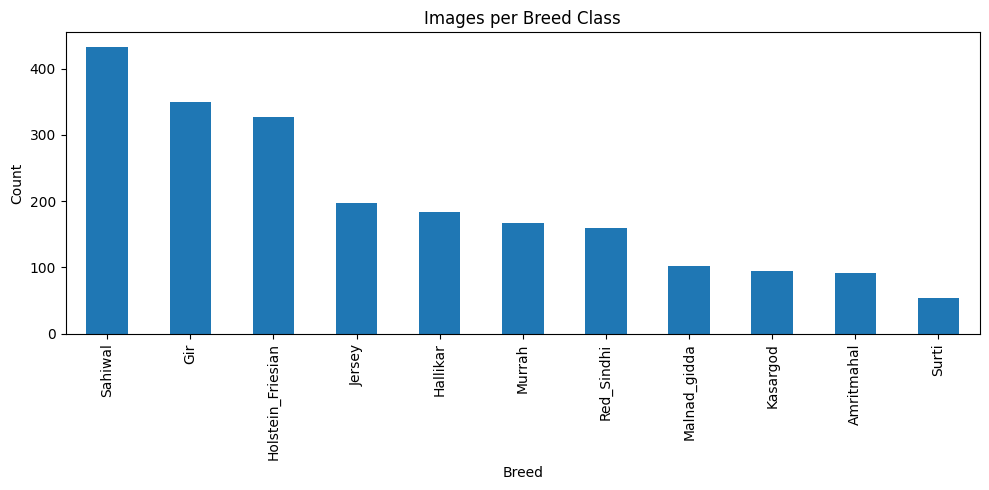

In [11]:
# STEP 7: Check class balance (bar chart)
# =========================================================
import pandas as pd
import matplotlib.pyplot as plt
 
df = pd.read_csv("C:\\Users\\Lenovo\\Downloads\\cattle_breed_dataset.csv")
 
df['breed'].value_counts().plot(kind='bar', figsize=(10,5), title='Images per Breed Class')
plt.xlabel("Breed")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

In [16]:
# STEP 8: Augment under-represented breed classes
# =========================================================
from PIL import Image, ImageEnhance, ImageOps
import os
import random
import pandas as pd
 
df = pd.read_csv("C:\\Users\\Lenovo\\Downloads\\cattle_breed_dataset.csv")
 
TARGET = 150  # set target count per breed as needed
 
def augment_breed(breed_name, target=TARGET):
    breed_df = df[df['breed'] == breed_name]
    current = len(breed_df)
    needed = target - current
 
    if needed <= 0:
        print(f"{breed_name}: already has {current} images, no augmentation needed")
        return
 
    print(f"Current {breed_name}: {current}")
    print(f"Need to generate: {needed} more images")
 
    save_folder = f"C:\\Users\\Lenovo\\Downloads\\cattle-breeds-cleaned\\{breed_name}\\"
    os.makedirs(save_folder, exist_ok=True)
 
    breed_paths = breed_df['image_path'].tolist()
 
    def augment_image(img):
        if random.random() > 0.5:
            img = ImageOps.mirror(img)
        angle = random.randint(-20, 20)
        img = img.rotate(angle)
        factor = random.uniform(0.8, 1.2)
        img = ImageEnhance.Brightness(img).enhance(factor)
        width, height = img.size
        crop_factor = random.uniform(0.85, 1.0)
        new_w = int(width * crop_factor)
        new_h = int(height * crop_factor)
        left = random.randint(0, width - new_w)
        top = random.randint(0, height - new_h)
        img = img.crop((left, top, left + new_w, top + new_h))
        img = img.resize((224, 224))
        return img
 
    generated = 0
    i = 0
    while generated < needed:
        img_path = breed_paths[i % current]
        img = Image.open(img_path).convert('RGB')
        img = augment_image(img)
        save_path = os.path.join(save_folder, f"aug_{breed_name}_{generated}.jpg")
        img.save(save_path)
        generated += 1
        i += 1
        print(f"Generated {generated}/{needed}", end='\r')
 
    print(f"\n✅ Generated {generated} new images for {breed_name}!")
    print(f"Total {breed_name} now: {current + generated}")
 
# Run for each breed below the target, e.g.:
# augment_breed("Persian")
# augment_breed("Siamese")
for breed in df['breed'].unique():
    augment_breed(breed)

Current Amritmahal: 92
Need to generate: 58 more images
Generated 58/58
✅ Generated 58 new images for Amritmahal!
Total Amritmahal now: 150
Gir: already has 350 images, no augmentation needed
Hallikar: already has 183 images, no augmentation needed
Holstein_Friesian: already has 327 images, no augmentation needed
Jersey: already has 197 images, no augmentation needed
Current Kasargod: 94
Need to generate: 56 more images
Generated 56/56
✅ Generated 56 new images for Kasargod!
Total Kasargod now: 150
Current Malnad_gidda: 102
Need to generate: 48 more images
Generated 48/48
✅ Generated 48 new images for Malnad_gidda!
Total Malnad_gidda now: 150
Murrah: already has 167 images, no augmentation needed
Red_Sindhi: already has 159 images, no augmentation needed
Sahiwal: already has 433 images, no augmentation needed
Current Surti: 54
Need to generate: 96 more images
Generated 96/96
✅ Generated 96 new images for Surti!
Total Surti now: 150


In [17]:
# STEP 9: Stratified train/val/test split
# =========================================================
import pandas as pd
from sklearn.model_selection import train_test_split
 
df = pd.read_csv("C:\\Users\\Lenovo\\Downloads\\cattle_breed_dataset.csv")
 
train, temp = train_test_split(df, test_size=0.3, stratify=df['breed'], random_state=42)
val, test = train_test_split(temp, test_size=0.5, stratify=temp['breed'], random_state=42)
 
os.makedirs("C:\\Users\\Lenovo\\Desktop\\CattleBreedClean", exist_ok=True)
train.to_csv("C:\\Users\\Lenovo\\Desktop\\CattleBreedClean\\cat_train.csv", index=False)
val.to_csv("C:\\Users\\Lenovo\\Desktop\\CattleBreedClean\\cat_val.csv", index=False)
test.to_csv("C:\\Users\\Lenovo\\Desktop\\CattleBreedClean\\cat_test.csv", index=False)
 
print(f"✅ Train: {len(train)}, Val: {len(val)}, Test: {len(test)}")

✅ Train: 1510, Val: 324, Test: 324


In [18]:
# =========================================================
# STEP 10: Final dataset verification
# =========================================================
import pandas as pd
from PIL import Image
import random
import os
 
df = pd.read_csv("C:\\Users\\Lenovo\\Downloads\\cattle_breed_dataset.csv")
train = pd.read_csv("C:\\Users\\Lenovo\\Desktop\\CattleBreedClean\\cat_train.csv")
val = pd.read_csv("C:\\Users\\Lenovo\\Desktop\\CattleBreedClean\\cat_val.csv")
test = pd.read_csv("C:\\Users\\Lenovo\\Desktop\\CattleBreedClean\\cat_test.csv")
 
# 1. No missing values
print("Missing values:")
print(df.isnull().sum())
 
# 2. All image sizes are 224x224
print("\nImage size and mode check:")
samples = random.sample(list(df['image_path']), 10)
for p in samples:
    img = Image.open(p)
    print(p, "→", img.size, img.mode)
 
# 3. No data leakage
overlap = set(train['image_path']).intersection(set(test['image_path']))
print("\nTrain-Test overlap:", len(overlap))
 
# 4. Class distribution in splits
print("\nTrain distribution:")
print(train['breed'].value_counts())
print("\nVal distribution:")
print(val['breed'].value_counts())
print("\nTest distribution:")
print(test['breed'].value_counts())
 
# 5. Check all images exist on disk
print("\nChecking images exist on disk...")
missing = [p for p in df['image_path'] if not os.path.exists(p)]
print(f"Missing images: {len(missing)} ← must be 0")
 
print("\n✅ Cattle breed dataset verification complete!")

Missing values:
image_path     0
animal_type    0
breed          0
dtype: int64

Image size and mode check:
C:\Users\Lenovo\Downloads\cattle-breeds-cleaned\Jersey\Jersey_166.jpg → (224, 224) RGB
C:\Users\Lenovo\Downloads\cattle-breeds-cleaned\Sahiwal\Sahiwal_314.jpg → (224, 224) RGB
C:\Users\Lenovo\Downloads\cattle-breeds-cleaned\Jersey\Jersey_145.jpg → (224, 224) RGB
C:\Users\Lenovo\Downloads\cattle-breeds-cleaned\Red_Sindhi\Red_Sindhi_114.jpg → (224, 224) RGB
C:\Users\Lenovo\Downloads\cattle-breeds-cleaned\Malnad_gidda\00000017.jpg → (224, 224) RGB
C:\Users\Lenovo\Downloads\cattle-breeds-cleaned\Holstein_Friesian\Holstein_Friesian_54.jpg → (224, 224) RGB
C:\Users\Lenovo\Downloads\cattle-breeds-cleaned\Hallikar\Hallikar_4.jpg → (224, 224) RGB
C:\Users\Lenovo\Downloads\cattle-breeds-cleaned\Sahiwal\Sahiwal_67.jpg → (224, 224) RGB
C:\Users\Lenovo\Downloads\cattle-breeds-cleaned\Kasargod\00000003.jpg → (224, 224) RGB
C:\Users\Lenovo\Downloads\cattle-breeds-cleaned\Murrah\Murrah_44.jpg → 